# p2.7: Is each feature of the student needed? (11/25/26)

*Part of phase 2: `p2_summary.ipynb` (section 12) connects this notebook with p2.1-p2.6.*

A fitted value says how much of a feature people's data wants; it doesn't say the feature is needed. That takes the
student without it, refitted where it has a value to refit, compared with people, by a rule fixed before the runs.
`MODEL.md` ("Why each feature is there") sorts every part of the student by that test. This notebook holds the tests
run for it:
1. **Salience** fitted to people's long attempts (moved from p2.6, section 11);
2. **is salience's parameter needed?** against a refitted soft memory, and its adoption (moved from p2.6, section 15);
3. **the flat-planning schedule** against a constant flat share;
4. **the opening rule** against none, both removed, and all three again at four seeds - after which the opening is
   dropped;
5. what the ledger says now;
6. **teaching on the final student**: stage 1's design played again on it.

The student throughout is the two-mode student (`spec.STUDENT`) on its start. Sections 1-2 play the start network on
people's 70 layouts (`experiments/fit_salience.py`) and sessions on people's puzzles
(`experiments/planner_session.py --lean`, the calibrated protocol at people's lengths, seeds 0 and 1), each session's
snapshots playing people's layouts at its stage (`fit_memory.py lean-snapshots`). Sections 3-4 use the same, from
`experiments/feature_tests.py`.

In [1]:
import json
import os
import sys
sys.path.insert(0, "..")
sys.path.insert(0, os.path.join("..", "experiments"))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import feature_tests as ft
import fit_memory as fm
import fit_salience as fs
from rushhour import human_data as hd, paths

SUMMARY = os.path.join(paths.MODELS, "summary")
INK, MUTED, RULE, GRID = "#1f1f1d", "#5f5e5a", "#b5b4ad", "#e6e5e0"
plt.rcParams.update({"font.size": 9, "axes.titlesize": 10, "axes.titlelocation": "left", "figure.dpi": 110,
                     "legend.frameon": False, "legend.fontsize": 8.5})


def tidy(ax, grid="y"):
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    for side in ("left", "bottom"):
        ax.spines[side].set_color(RULE)
    ax.tick_params(colors=MUTED)
    if grid:
        ax.grid(axis=grid, color=GRID, lw=0.8)
    ax.set_axisbelow(True)


STAGE_BINS = [(1, 9), (10, 27), (28, 45), (46, 72)]


def curve(records):
    out = {}
    for lo, hi in STAGE_BINS:
        es = [e for e in records if lo <= e["trial"] <= hi]
        won = [e for e in es if e["solved"]]
        out[f"{lo}-{hi}"] = f"{np.mean([e['solved'] for e in es]):.2f} / " \
                            f"{np.mean([e['moves'] / e['distance'] for e in won]):.2f}"
    return out


def session_records(run):
    d = json.load(open(os.path.join(paths.SESSIONS, run, "no_teacher", "sessions.json")))
    return [e for r in d.values() for e in r]


def snapshot_table(runs):
    snap = []
    for name, run in runs.items():
        out, _ = fm.summarize_learning(pd.read_csv(os.path.join(SUMMARY, f"lean_snapshots_{run}.csv")), fm.SNAP_STAGES)
        out = out[[r.snapshot == fm.SNAP_OF[r.stage] for r in out.itertuples()]]
        snap += [{"run": name, "stage": r["stage"], "skill misfit": r["skill misfit"],
                  "revisit misfit": r["revisit misfit"]} for _, r in out.iterrows()]
    snap = pd.DataFrame(snap).pivot(index="run", columns="stage").reindex(columns=list(fm.SNAP_STAGES), level=1)
    snap[("skill misfit", "mean")] = snap["skill misfit"].mean(axis=1)
    snap[("revisit misfit", "mean")] = snap["revisit misfit"].mean(axis=1)
    return snap.reindex(list(runs))


tp = hd.trials()  # people: per person, then across people (as in p2.2)
people_curve = {}
for lo, hi in STAGE_BINS:
    g = tp[tp.trial.between(lo, hi)]
    w = g[g.solved]
    people_curve[f"{lo}-{hi}"] = f"{g.groupby('subject').solved.mean().mean():.2f} / " \
                                 f"{(w.moves / w.distance).groupby(w.subject).mean().mean():.2f}"

## 1. Salience: coming back to the same boards

*(Moved from p2.6, section 11.)* The soft memory as it was (β 2, half-life 1) forgets a board within a few moves. In
long attempts the student kept coming back to the same boards: past 8 × optimal, 55% of its returns were to a board it
had already visited twice, against people's 37% (p2.6, section 8). People seem to notice a board they keep returning
to. **Salience** (`solve_two_mode(salience=(λ, half-life))`) adds a trace λ to a board's soft-memory penalty for every
return after the first, summed over returns and fading by half every half-life moves, or never. A board's first return
is penalized as before.

**The fit** (`experiments/fit_salience.py` → `models/summary/salience/fit.csv`): the start network plays people's 70
layouts as the two-mode student, 10 times each, to max(50, 10 × optimal) moves without giving up, for λ 0.5-4 ×
half-life 8, 32 or never. It is fitted to people's returns in attempts of 5-10 × optimal (**long misfit**: third+
visits, the share of returns to a board visited twice already, and the most visits to one board), and checked on
fit_memory's revisit misfit at matched efficiency (**matched misfit**), which the soft memory was fitted to.

In [2]:
fs.summary().style.format("{:.3f}").set_caption("people's 70 layouts; third+ and max visits by attempt length (× optimal)")

,matched misfit,solved,third+ 3-5,third+ 5-8,third+ 8-10,max visits 5-8,max visits 8-10,long misfit
people,nan,0.703,0.227,0.307,0.369,3.770,4.917,0.000
none,0.023,0.689,0.299,0.367,0.549,4.542,8.684,0.904
"lam 0.5, half-life 8",0.017,0.686,0.226,0.372,0.484,4.485,6.771,0.318
"lam 0.5, half-life 32",0.020,0.699,0.218,0.328,0.432,3.964,5.797,0.067
"lam 0.5, half-life inf",0.019,0.696,0.220,0.307,0.398,3.830,5.066,0.007
"lam 1, half-life 8",0.016,0.689,0.211,0.279,0.436,3.560,6.036,0.095
"lam 1, half-life 32",0.019,0.713,0.169,0.268,0.363,3.495,4.813,0.022
"lam 1, half-life inf",0.018,0.694,0.184,0.227,0.309,3.307,4.183,0.132
"lam 2, half-life 8",0.015,0.694,0.163,0.215,0.391,3.250,5.213,0.116
"lam 2, half-life 32",0.014,0.694,0.130,0.194,0.277,3.062,4.013,0.267


- **λ 0.5, never fading, fits the long attempts** (long misfit 0.007, the soft memory alone 0.90): third+ visits
  31% / 40% at 5-8 / 8-10 × optimal (people 31% / 37%; soft 37% / 55%), the most visits to one board 3.8 / 5.1
  (people 3.8 / 4.9; soft 4.5 / 8.7).
- **It leaves the rest as it was**: matched misfit 0.019 (soft 0.023), 70% solved (soft 69%, people 70%).
- **Stronger salience makes the student loop less than people**: λ 2-4 cut third+ visits at 8-10 × to 13-28%.

**On the teaching tests** (`experiments/salience_test.py` → `models/summary/salience/test.csv`; the setup of p2.6,
section 7, with phase 1's hard memory from p2.6, section 4).

In [3]:
sal = pd.read_csv(os.path.join(SUMMARY, "salience", "test.csv"))
hard = pd.read_csv(os.path.join(SUMMARY, "solve_rate", "attempts.csv")).query("play == 'intuition, hard memory'")
both = pd.concat([sal, hard[hard.network.isin(sal.network.unique())]])
both.pivot_table(index="network", columns="play", values="solved").reindex(columns=[
    "two-mode", "salience: lam 0.5, never fades", "salience: lam 1, half-life 32", "intuition, hard memory"]).style \
    .format("{:.3f}").set_caption("solved, test puzzles (9-26 moves, cap 10 × optimal, no giving up)")

play,two-mode,"salience: lam 0.5, never fades","salience: lam 1, half-life 32","intuition, hard memory"
network,,,,
after two-mode session,0.576,0.623,0.631,0.672
start,0.562,0.629,0.621,0.668


- **Salience closes about half the gap** between the soft and hard memories on the tests: 56-58% → 62-63%, against
  the hard memory's 67-68%.

**In a session**: the lean session played again with salience (`planner_session.py --salience 0.5 0`;
`lean_people_all_m10_ao_b2_salience[_seed1]`), against the soft-memory runs (`lean_people_all_m10_ao_b2[_seed1]`) and
people: solved and moves / optimal on solved puzzles while playing, by stage of the session; and each stage's
snapshot playing people's layouts, against that stage's people.

In [4]:
LEAN_RUNS = {"soft, seed 0": "lean_people_all_m10_ao_b2", "soft, seed 1": "lean_people_all_m10_ao_b2_seed1",
             "salient, seed 0": "lean_people_all_m10_ao_b2_salience",
             "salient, seed 1": "lean_people_all_m10_ao_b2_salience_seed1"}
curves = pd.DataFrame({"people": people_curve} | {n: curve(session_records(r)) for n, r in LEAN_RUNS.items()}).T
ratio = curves.apply(lambda c: c.str.split(" / ").str[1].astype(float))
curves["gain"] = ratio["1-9"] - ratio["46-72"]
display(curves.style.format({"gain": "{:.2f}"}).set_caption("solved / moves ÷ optimal (solved), while playing"))
snapshot_table(LEAN_RUNS).style.format("{:.3f}").set_caption("each stage's snapshot on people's layouts, against that stage's people")

,1-9,10-27,28-45,46-72,gain
people,0.88 / 2.77,0.89 / 2.53,0.88 / 2.36,0.84 / 2.17,0.60
"soft, seed 0",0.83 / 2.81,0.86 / 2.51,0.85 / 2.39,0.85 / 2.29,0.52
"soft, seed 1",0.83 / 2.74,0.85 / 2.50,0.85 / 2.29,0.85 / 2.24,0.50
"salient, seed 0",0.85 / 2.83,0.88 / 2.45,0.86 / 2.32,0.87 / 2.30,0.53
"salient, seed 1",0.85 / 2.88,0.86 / 2.49,0.85 / 2.36,0.88 / 2.31,0.57


- **The session is as human as before**: salience starts at 2.83-2.88 moves / optimal (people 2.77, soft 2.74-2.81)
  and gains 0.53-0.57 over the session (people 0.60, soft 0.50-0.52), solving 85-88% (people 84-89%).
- **Snapshots**: the revisit misfit is about the same or lower at every stage. The skill misfit is a little worse
  overall, most at 46+ on seed 0 (0.97 against the soft memory's 0.59-0.65).

So salience passed this first check. p2.6 (sections 12-14) then taught this salient student; section 2 asks whether
its extra parameter is needed at all.

## 2. Is salience's parameter needed? The memory refitted

*(Moved from p2.6, section 15.)* Salience adds a parameter, so it should beat the simpler model refitted, not the soft
memory as it stood. That soft memory (β 2, half-life 1) was fitted for the intuition student, never for this one.

**The soft memory alone, refitted** (`experiments/fit_salience.py refit` → `models/summary/salience/refit.csv`): β 1-8
× half-life 0.5-8, on people's layouts with the same draws as section 1 (β 2, half-life 1 reproduces it move for move).
Held-out misfit: the bins of 1.5-5 × optimal, which neither fit used.

In [5]:
fs.summary(refit=True).style.format("{:.3f}").set_caption("soft memory alone, refitted; "
                                                            "the fitted salience for comparison")

,matched misfit,solved,third+ 1.5-3,third+ 3-5,third+ 5-8,third+ 8-10,max visits 5-8,max visits 8-10,long misfit,held-out misfit
people,nan,0.703,0.163,0.227,0.307,0.369,3.770,4.917,0.000,0.000
none,0.023,0.689,0.190,0.299,0.367,0.549,4.542,8.684,0.904,0.166
"lam 0.5, half-life inf",0.019,0.696,0.143,0.220,0.307,0.398,3.830,5.066,0.007,0.016
"soft beta 1, half-life 0.5",0.061,0.657,0.225,0.302,0.366,0.577,4.609,9.755,1.370,0.321
"soft beta 1, half-life 1",0.047,0.679,0.222,0.274,0.379,0.560,4.478,9.335,1.162,0.213
"soft beta 1, half-life 2",0.019,0.686,0.184,0.305,0.393,0.533,4.676,8.078,0.744,0.170
"soft beta 1, half-life 4",0.007,0.681,0.165,0.323,0.375,0.507,4.329,7.391,0.462,0.203
"soft beta 1, half-life 8",0.008,0.689,0.135,0.240,0.318,0.492,3.825,7.157,0.320,0.037
"soft beta 2, half-life 0.5",0.053,0.653,0.222,0.285,0.384,0.568,4.812,9.234,1.198,0.239
"soft beta 2, half-life 1",0.023,0.689,0.190,0.299,0.367,0.549,4.542,8.684,0.904,0.166


- **The soft memory was out of date for this student**: β 2, half-life 2 fits its own target (revisit ages at
  matched efficiency) 4-5 × better than β 2, half-life 1 (0.004 against 0.023) and the held-out bins as well as
  salience.
- **No soft memory fits short and long attempts at once.** The best fits form a ridge, and along it, settings that
  match people past 5 × optimal (β 6 with half-life 2; β 2 with 8) make short attempts loop too little: third+ visits
  of 0.05-0.11 at 1.5-3 × optimal, against people's 0.16.

**Both refitted together** (`fit_salience.py joint` → `models/summary/salience/joint.csv`): the soft memory over β 1-4
× half-life 1, 2, 4, each with salience λ 0.25, 0.5 or 1 (never fading, the simplest) and without. Scored, as fixed
before the run, by the **shape of looping across attempt lengths**: χ² over the four bins of 1.5-10 × optimal and both
statistics, each gap divided by people's standard error, so thin bins weigh less. Salience earns its parameter if the
best model with it lowers χ² by more than 3.84 (one parameter's likelihood-ratio cut) against the best without, with a
matched misfit no more than 0.01 worse. People's standard errors resample attempts (the loops table has no person
ids), so they are understated.

In [6]:
joint = fs.joint_summary()
show = ["parameters", "matched misfit", "chi2", "chi2 short", "chi2 long"] + \
       [f"third+ {l}" for l in fs.SHAPE_BINS] + [f"max visits {l}" for l in fs.SHAPE_BINS]
joint[show].head(14).style.format("{:.3f}", na_rep="").set_caption("the 12 best by χ², under people and their SE")

,parameters,matched misfit,chi2,chi2 short,chi2 long,third+ 1.5-3,third+ 3-5,third+ 5-8,third+ 8-10,max visits 1.5-3,max visits 3-5,max visits 5-8,max visits 8-10
people,,,,,,0.163,0.227,0.307,0.369,2.051,2.823,3.770,4.917
people SE,,,,,,0.009,0.013,0.026,0.030,0.028,0.068,0.182,0.378
"soft beta 1, half-life 2, lam 0.5",3.000,0.022,5.645,4.406,1.239,0.146,0.217,0.326,0.387,2.066,2.826,3.878,5.000
"soft beta 2, half-life 1, lam 0.5",3.000,0.019,7.801,6.641,1.159,0.143,0.220,0.307,0.398,2.084,2.847,3.830,5.066
"soft beta 1, half-life 4, lam 0.5",3.000,0.007,14.063,13.228,0.835,0.151,0.205,0.297,0.372,1.970,2.797,3.646,4.740
"soft beta 3, half-life 1, lam 0.25",3.000,0.007,29.875,12.318,17.557,0.156,0.210,0.371,0.432,1.963,2.810,4.081,5.718
"soft beta 1, half-life 1, lam 0.5",3.000,0.035,31.577,30.241,1.336,0.156,0.241,0.282,0.387,2.170,3.042,3.754,5.025
"soft beta 3, half-life 1, lam 0.5",3.000,0.007,37.708,35.482,2.226,0.144,0.194,0.285,0.383,1.926,2.680,3.562,4.955
"soft beta 1, half-life 4, lam 0.25",3.000,0.007,43.587,28.051,15.535,0.146,0.201,0.370,0.425,1.925,2.870,4.111,5.564
"soft beta 2, half-life 1, lam 1",3.000,0.018,52.489,28.911,23.578,0.133,0.184,0.227,0.309,2.087,2.664,3.307,4.183


- **Salience earns its parameter.** The best soft memory alone (β 2, half-life 2) scores χ² 109; with salience,
  soft β 1, half-life 4 and λ 0.5 scores 14, within the matched cut (0.007 against 0.004). The gap stays far past the
  cut even with people's standard errors doubled.
- **The miss isn't only in the thin bins.** The soft memory alone misses short attempts too (χ² short 51): at 1.5-3 ×
  optimal its most visits to one board is 1.86 against people's 2.05 ± 0.03.
- **λ 0.5 is best at every soft memory.** With salience handling repeated returns, the soft memory fits best weaker and
  slower to fade: a mild, lasting aversion to recent boards, plus a strong one to boards that keep coming back.
- **The two with lower χ² fail the matched cut**: soft β 1, half-life 2 with λ 0.5 (5.6) and section 1's salient
  student, β 2, half-life 1 with λ 0.5 (7.8), at matched misfits of 0.022 and 0.019.

**In a session** (`planner_session.py --lean --soft-memory 1 4 --salience 0.5 0`;
`lean_people_all_m10_ao_b2_joint[_seed1]`), as section 1's check.

In [7]:
LEAN_RUNS2 = {"soft (2, 1), seed 0": "lean_people_all_m10_ao_b2", "soft (2, 1), seed 1": "lean_people_all_m10_ao_b2_seed1",
              "salient (2, 1) + 0.5, seed 0": "lean_people_all_m10_ao_b2_salience",
              "salient (2, 1) + 0.5, seed 1": "lean_people_all_m10_ao_b2_salience_seed1",
              "joint (1, 4) + 0.5, seed 0": "lean_people_all_m10_ao_b2_joint",
              "joint (1, 4) + 0.5, seed 1": "lean_people_all_m10_ao_b2_joint_seed1"}
curves2 = pd.DataFrame({"people": people_curve} | {n: curve(session_records(r)) for n, r in LEAN_RUNS2.items()}).T
ratio2 = curves2.apply(lambda c: c.str.split(" / ").str[1].astype(float))
curves2["gain"] = ratio2["1-9"] - ratio2["46-72"]
display(curves2.style.format({"gain": "{:.2f}"}).set_caption("solved / moves ÷ optimal (solved), while playing"))
snapshot_table(LEAN_RUNS2).style.format("{:.3f}").set_caption("each stage's snapshot on people's layouts")

,1-9,10-27,28-45,46-72,gain
people,0.88 / 2.77,0.89 / 2.53,0.88 / 2.36,0.84 / 2.17,0.60
"soft (2, 1), seed 0",0.83 / 2.81,0.86 / 2.51,0.85 / 2.39,0.85 / 2.29,0.52
"soft (2, 1), seed 1",0.83 / 2.74,0.85 / 2.50,0.85 / 2.29,0.85 / 2.24,0.50
"salient (2, 1) + 0.5, seed 0",0.85 / 2.83,0.88 / 2.45,0.86 / 2.32,0.87 / 2.30,0.53
"salient (2, 1) + 0.5, seed 1",0.85 / 2.88,0.86 / 2.49,0.85 / 2.36,0.88 / 2.31,0.57
"joint (1, 4) + 0.5, seed 0",0.85 / 2.78,0.88 / 2.50,0.88 / 2.38,0.89 / 2.27,0.51
"joint (1, 4) + 0.5, seed 1",0.86 / 2.76,0.87 / 2.52,0.88 / 2.42,0.88 / 2.22,0.54


- **It passes**: it starts closest to people (2.76-2.78 against 2.77), gains as much as the soft memory alone
  (0.51-0.54; people 0.60), and its snapshots fit people's revisits better at every stage (mean 0.037-0.043, against
  0.068-0.073). Skill is about the soft memory's; as for the salient student, seed 0's last stage is the weak one.

**So the student's memory is now soft β 1, half-life 4, plus salience λ 0.5** (`spec.TWO_MODE`, 2026-11-25). p2.6's
teaching runs are on the earlier memories (`spec.SOFT`; the salient student); none has this one yet. Since loop-aware
bayes4's gain didn't depend on the memory (p2.6, section 13), they should carry over. Sections 3-4 use this student.

## 3. The flat-planning schedule

The student's flat-planning share rises from 6% of moves in trial 1 to 18% by trial 30 (3 settings: start, end and
ramp), as people's moves fit flat planning more as the session's networks learn (p2.2, section 2c). Its learning curve
was never compared with a student whose flat share stays put. **The simpler model**: a constant share (1 setting),
refitted over 6%, 12% and 18% (`experiments/feature_tests.py` → runs `lean_people_all_m10_ao_b2_joint_flat<6|12|18>`
and `_seed1`).

**The rule, fixed before the runs**: score each student's learning curve by χ² over the 4 stages of trials (1-9,
10-27, 28-45, 46-72) of moves / optimal on solved puzzles and the solve rate, each gap from people over people's SE
(resampling people), the student being the mean of its two seeds. The schedule is needed if the best constant's χ² is
more than 5.99 above the schedule's (two parameters' likelihood-ratio cut). The snapshots' skill and revisit misfits
are reported beside it.

,chi2,m/o 1-9,m/o 10-27,m/o 28-45,m/o 46-72,solved 1-9,solved 10-27,solved 28-45,solved 46-72,gain,skill misfit,revisit misfit
people,0.000,2.771,2.526,2.362,2.173,0.876,0.886,0.881,0.838,0.60,,
people SE,,0.165,0.134,0.220,0.111,0.027,0.020,0.024,0.043,,,
"schedule, opening",2.473,2.766,2.509,2.398,2.245,0.853,0.877,0.881,0.883,"0.51, 0.53",0.600,0.040
noopen,3.002,2.784,2.540,2.357,2.283,0.856,0.879,0.882,0.888,"0.56, 0.44",0.671,0.045
flat6,2.890,2.757,2.462,2.351,2.250,0.858,0.869,0.868,0.877,"0.51, 0.50",0.595,0.049
flat12,1.557,2.769,2.558,2.356,2.232,0.867,0.878,0.873,0.878,"0.52, 0.56",0.601,0.046
flat18,2.582,2.695,2.466,2.345,2.295,0.874,0.881,0.876,0.877,"0.40, 0.40",0.659,0.049
noopen_flat12,3.598,2.717,2.529,2.370,2.321,0.865,0.881,0.870,0.887,"0.39, 0.40",0.699,0.050


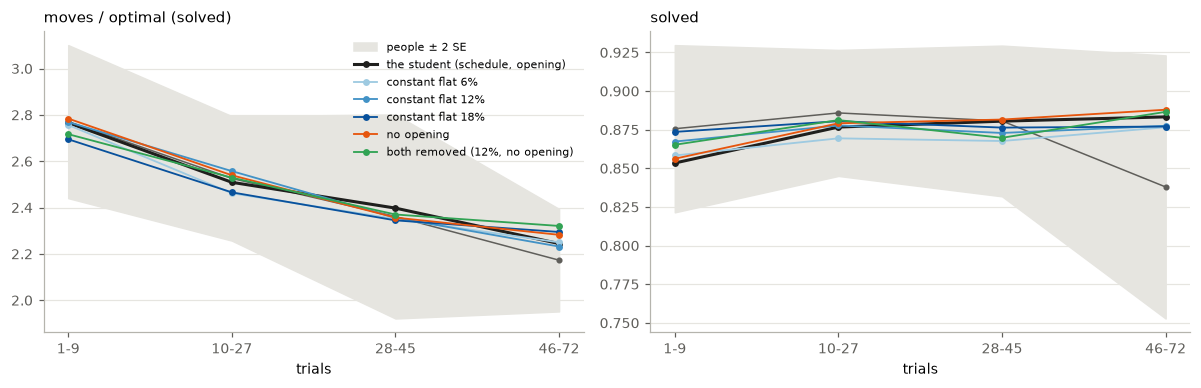

In [8]:
curves_ft = ft.curve_summary()
display(curves_ft.style.format("{:.3f}", na_rep="", subset=[c for c in curves_ft.columns if c != "gain"])
        .format(lambda g: ", ".join(f"{x:.2f}" for x in g) if isinstance(g, list) else f"{g:.2f}" if g == g else "",
                subset=["gain"])
        .set_caption("learning curve: the mean of seeds 0-1 (gain per seed), against people"))

FT_COLORS = {"schedule, opening": INK, "flat6": "#9ecae1", "flat12": "#4292c6", "flat18": "#08519c",
             "noopen": "#e6550d", "noopen_flat12": "#31a354"}
FT_LABELS = {"schedule, opening": "the student (schedule, opening)", "flat6": "constant flat 6%",
             "flat12": "constant flat 12%", "flat18": "constant flat 18%", "noopen": "no opening",
             "noopen_flat12": "both removed (12%, no opening)"}
stages = [f"{lo}-{hi}" for lo, hi in ft.STAGES]
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
for ax, stat, label in [(axes[0], "m/o", "moves / optimal (solved)"), (axes[1], "solved", "solved")]:
    people = curves_ft.loc["people", [f"{stat} {s}" for s in stages]].astype(float)
    se = curves_ft.loc["people SE", [f"{stat} {s}" for s in stages]].astype(float)
    ax.fill_between(range(4), people - 2 * se, people + 2 * se, color=GRID, label="people ± 2 SE")
    ax.plot(range(4), people, "o-", color=MUTED, lw=1, ms=3)
    for v in ["schedule, opening", "flat6", "flat12", "flat18", "noopen", "noopen_flat12"]:
        ax.plot(range(4), curves_ft.loc[v, [f"{stat} {s}" for s in stages]].astype(float), "o-", ms=3.5,
                color=FT_COLORS[v], label=FT_LABELS[v], lw=2 if v == "schedule, opening" else 1.2)
    ax.set_xticks(range(4), stages)
    ax.set_xlabel("trials")
    ax.set_title(label)
    tidy(ax)
axes[0].legend(fontsize=7.5)
plt.tight_layout()
plt.show()

- **By the rule, the schedule isn't needed.** A constant 12% fits the learning curve as well (χ² 1.6, against the
  schedule's 2.5); the rule asked for the best constant to be more than 5.99 worse. It starts where people do (2.77
  moves / optimal; people 2.77), gains 0.52-0.56 over the session (the schedule 0.51-0.53; people 0.60), and its
  snapshots fit people's layouts alike (skill misfit 0.60 against 0.60; revisits 0.046 against 0.040).
- **The test has little power.** Every variant scores χ² 1.6-3.0 over 8 statistics: people's stage means have wide
  standard errors (0.11-0.22 moves / optimal), so the learning curve can't tell these students apart. Even a constant
  18%, which gains only 0.40, scores 2.6. With no difference the data can see, parsimony decides: one setting instead
  of three.
- **People's moves do show the rise.** The move-by-move mixture gives flat planning 6% → 18% with each stage's network,
  rising for 27 of 37 people (p2.2, section 2c).
- **At four seeds the schedule is needed after all** (section 4, "Four seeds"): a constant 12% makes the student's
  revisits a little less like people's, a difference the learning curve can't see.

## 4. The opening rule

The opening: an attempt's first move is always a deliberation (one AND-OR pass), and its second is the same pass's
second move. It came from people's moves: a slow first look at a puzzle, and a move after it that fits AND-OR more
than moves after a slow move mid-attempt (14% against 4%; p2.2, section 2c). It has no value to refit, so **the simpler
model** is the student without it (runs `lean_people_all_m10_ao_b2_joint_noopen[_seed1]`).

It acts on two moves an attempt, which a session's statistics barely see, so it is also scored **where it acts**: the
start network plays people's 70 layouts (10 runs each, the same draws) with and without it, and the share of its
first and second moves that are optimal (2+ moves from the goal) is compared with people's in trials 1-9
(`feature_tests.py first-moves` → `models/summary/feature_tests/first_moves.csv`).

**The rule, fixed before the runs**: the opening is needed if, without it, χ² of the first two moves' share optimal
against people (each gap over the two shares' combined SE) is more than 3.84 above the student's with it, or the
learning curve's χ² (section 3) is.

,move 1,move 1 se,move 1 n,move 2,move 2 se,move 2 n,moves 3-6,moves 3-6 se,moves 3-6 n,chi2 moves 1-2
who,,,,,,,,,,
people,0.469,0.022,497,0.416,0.022,495,0.499,0.011,1906,0.000
with the opening,0.541,0.019,700,0.529,0.019,700,0.436,0.009,2774,21.046
without,0.473,0.019,700,0.449,0.019,700,0.442,0.009,2778,1.261
"without, flat 12%",0.487,0.019,700,0.454,0.019,700,0.450,0.009,2777,2.108


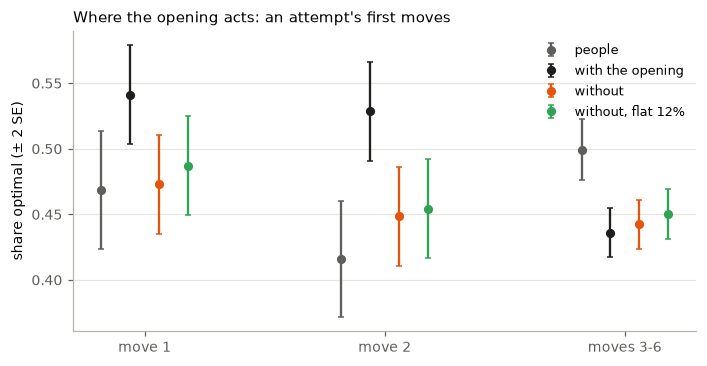

In [9]:
first = ft.first_summary()
display(first.style.format("{:.3f}").format("{:.0f}", subset=[c for c in first.columns if c.endswith(" n")])
        .set_caption("share of moves optimal, 2+ moves from the goal: people in trials 1-9, the start network"))
fig, ax = plt.subplots(figsize=(6.5, 3.4))
cols = ["move 1", "move 2", "moves 3-6"]
for k, (who, color) in enumerate([("people", MUTED), ("with the opening", INK), ("without", "#e6550d"),
                                  ("without, flat 12%", "#31a354")]):
    ax.errorbar(np.arange(3) + (k - 1.5) * 0.12, first.loc[who, cols].astype(float),
                yerr=2 * first.loc[who, [f"{c} se" for c in cols]].astype(float), fmt="o", ms=5, capsize=2,
                color=color, label=who)
ax.set_xticks(range(3), cols)
ax.set_ylabel("share optimal (± 2 SE)")
ax.set_title("Where the opening acts: an attempt's first moves")
ax.legend()
tidy(ax)
plt.tight_layout()
plt.show()

- **The opening makes the first two moves too good.** With it, the start network's first and second moves are
  optimal 54% and 53% of the time; people's in trials 1-9, 47% and 42%; without it, 47% and 45%. χ² of the first two
  moves is 21.0 with the opening and 1.3 without: the opening fits people worse where it acts, far past the cut.
- **The session doesn't need it either.** The learning curve's χ² is 3.0 without it and 2.5 with it (the cut is 3.84
  above), the gain 0.44-0.56 against 0.51-0.53, and the snapshots are alike (skill misfit 0.67 against 0.60; revisits
  0.045 against 0.040).
- **What this test doesn't see.** The opening came from which kind of move people make after a slow first look (more
  AND-OR-like than after a slow move mid-attempt), not from how good it is. This test scores only optimality: an
  AND-OR pass's first move is more often optimal than an intuitive one, so a student that always opens with it starts
  each attempt better than people do. Testing the AND-OR-likeness itself would take the move-by-move mixture with and
  without an opening term.
- Moves 3-6 are a little less often optimal for the student than for people either way (44% against 50%): the start
  network finds people's layouts harder than the pool puzzles it was fitted on (p2_summary, section 7). Its first moves
  without the opening still match people's.

**Both removed.** A student with a constant 12% and no opening is neither test's student, so it was run as well
(runs `lean_people_all_m10_ao_b2_joint_noopen_flat12[_seed1]`; in the tables and figures above as `noopen_flat12` and
"without, flat 12%"). **The rule, fixed before its runs**: it may replace the student if its learning curve's χ² is no
more than 3.84 above the student's, its snapshots' skill and revisit misfits are no worse than the worse of the
student's two seeds, and its first two moves' χ² is no more than 3.84 above the student's.

In [10]:
seeds = {v: [ft.snapshots(ft.run_name(None if v == "schedule, opening" else v, s)) for s in (0, 1)]
         for v in ["schedule, opening", "noopen_flat12"]}
pd.DataFrame({v: {"curve chi2": curves_ft.loc[v, "chi2"], "first two moves chi2": first.loc[w, "chi2 moves 1-2"],
                  "skill misfit, seeds 0 / 1": " / ".join(f"{x[0]:.3f}" for x in seeds[v]),
                  "revisit misfit, seeds 0 / 1": " / ".join(f"{x[1]:.3f}" for x in seeds[v]),
                  "gain, seeds 0 / 1": " / ".join(f"{g:.2f}" for g in curves_ft.loc[v, "gain"])}
              for v, w in [("schedule, opening", "with the opening"), ("noopen_flat12", "without, flat 12%")]}).T

,curve chi2,first two moves chi2,"skill misfit, seeds 0 / 1","revisit misfit, seeds 0 / 1","gain, seeds 0 / 1"
"schedule, opening",2.473078,21.04607,0.677 / 0.523,0.037 / 0.043,0.51 / 0.53
noopen_flat12,3.598484,2.107907,0.755 / 0.643,0.049 / 0.052,0.39 / 0.40


- **At two seeds it fails the rule.** Its first two moves fit people (χ² 2.1, against the student's 21.0), and its
  learning curve is within the cut (χ² 3.6 against 2.5). But its snapshots fit people's layouts worse than the
  student's worse seed: in skill at seed 0 (0.755 and 0.643, against the student's 0.677 and 0.523), and in revisits
  at both seeds (0.049 and 0.052, against 0.037 and 0.043). It also gained only 0.39 and 0.40 moves / optimal (the
  student 0.51 and 0.53).
- **That rule turned out too strict.** The single removals miss it too, by less than the student's own two seeds
  differ (revisits 0.045-0.048 against 0.043). Two seeds can't separate these students, so all three were run at four
  seeds, below.

**Four seeds.** Two seeds couldn't tell the single removals from the student: their snapshots missed the "worse
seed" rule by less than the student's own two seeds differ. So the student, a constant 12%, no opening and both
removed got seeds 2 and 3 as well (`feature_tests.py`, `FOUR_SEEDS`). **The rule, fixed before these runs**: per seed,
four measures, each oriented so larger is worse - the start's distance from people's (moves / optimal in trials 1-9),
the gain's distance from people's, and the snapshots' mean skill and revisit misfits. A simplification passes if, on
every measure, its four-seed mean is no more than 2 SE worse than the student's, the SE from the spread between seeds
(Welch). Which to drop: both, if both removed passes; else the schedule, if it passes (it removes two settings, the
opening one); else the opening, if it passes; else neither.

In [11]:
rule, passes, decision = ft.four_seed_rule()
per_seed = pd.concat({v or "the student": ft.seed_measures(v)[["start", "gain", "skill misfit", "revisit misfit"]]
                      for v in ft.FOUR_SEEDS}, names=["variant"])
display(per_seed.style.format("{:.3f}").set_caption("per seed: start and gain (moves / optimal; people 2.77 and 0.60), "
                                                     "snapshot misfits"))
display(rule.style.format("{:.3f}", subset=["student", "variant mean", "worse by", "se"])
        .set_caption("four-seed means of the measures (larger is worse); passes: worse by ≤ 2 SE"))
print("passes:", passes.to_dict(), "| decision:", decision)

,variant,measure,student,variant mean,worse by,se,passes
0,flat12,start off,0.037,0.071,0.034,0.042,True
1,flat12,gain off,0.116,0.151,0.035,0.059,True
2,flat12,skill misfit,0.634,0.622,-0.013,0.054,True
3,flat12,revisit misfit,0.041,0.048,0.007,0.003,False
4,noopen,start off,0.037,0.054,0.017,0.022,True
5,noopen,gain off,0.116,0.137,0.021,0.042,True
6,noopen,skill misfit,0.634,0.683,0.049,0.046,True
7,noopen,revisit misfit,0.041,0.044,0.003,0.002,True
8,noopen_flat12,start off,0.037,0.039,0.002,0.024,True
9,noopen_flat12,gain off,0.116,0.150,0.035,0.051,True


passes: {'flat12': False, 'noopen': True, 'noopen_flat12': False} | decision: drop the opening


- **The opening goes.** Without it the student passes all four measures: its skill misfit is the closest call
  (0.049 worse, against 2 SE of 0.092), and its start, gain and revisits are within noise. With its first moves
  fitting people better (section 4), the student is now without it (`spec.TWO_MODE`, `opening` off).
- **The schedule stays.** A constant 12% fails on revisits: 0.048 against 0.041, 0.007 worse with an SE of 0.003. The
  revisit misfit barely varies between seeds, so even this small difference is clear: with flat planning at 12% from
  the start, the student's revisits are a little less like people's. Its start and gain also vary more between seeds
  (gain 0.33-0.56).
- **Both removed fails the same way** (revisits 0.048). Its gain was not as low as two seeds suggested: 0.39-0.59 over
  four seeds (the student 0.44-0.53), within noise. The two-seed reading that the removals interact was mostly seed
  noise; what separates both-removed from the student is the constant flat share's revisits.
- **Seeds matter.** The student's own gain runs 0.44-0.53 over four seeds and its start 2.69-2.78. Two seeds per
  student are too few to compare students by snapshots or gain.

## 5. What the ledger says now

| Feature | The simpler model | Rule | Result |
|---|---|---|---|
| Salience (1 setting) | the soft memory alone, refitted | χ² of looping's shape > 3.84 worse | **needed**: 109 against 14; adopted (section 2) |
| The flat schedule (3 settings) | a constant flat share, refitted (12%) | four seeds: no measure > 2 SE worse | **needed**: revisits 0.007 worse (SE 0.003); kept |
| The opening (a switch) | no opening | four seeds: no measure > 2 SE worse; first moves | **not needed**, and worse where it acts (first moves χ² 21.0 with it, 1.3 without); **dropped** |

- **The student is now without the opening** (`spec.TWO_MODE`, 2026-11-25): the joint memory, the flat schedule, AND-OR
  at 18% of moves, no opening. Stage 1's teaching conclusions hold on it (section 6).
- **The start holds for every variant.** The start (round 1 epoch 3, giving up × 0.40) was fitted by intuition, not by
  the two-mode student; every variant here starts at 2.62-2.83 moves / optimal in trials 1-9, against people's 2.77.
- **What these tests can and can't decide.** The learning curve's χ² can't separate these students; at two seeds,
  neither can the snapshots or the gain. At four seeds the revisit misfit can, since it barely varies between seeds.
  The opening was motivated by which kind of move people make after a slow first look; that move-type evidence is
  untested here and would take the move-by-move mixture with and without an opening term.

## 6. Teaching on the final student

The student changed twice since stage 1 (p2.6, section 13): its memory is the joint one (β 1, half-life 4, salience
0.5; section 2), not salience on the old soft memory, and it has no opening (section 4). Stage 1's design was played
again on it, to check that stage 1's conclusions carry over (`experiments/final_queue.py`, runs
`joint_noopen_m10[_s<seed>]_agency<a>`): ΔA 0.1, 0.5 and 1, seeds 0-2 (24 students); teachers none (at ΔA 1 only),
bayes4, loop-aware bayes4 (`bayes4:0.45,loops=1`) and random 10%. The comparisons are stage 1's, fixed before the runs,
each paired by student at each ΔA:
1. bayes4 against no teacher;
2. loop-aware bayes4 against bayes4;
3. loop-aware bayes4 against random 10%.

Primary: the end score (moves / optimal, an unsolved attempt at its cap) on the end test's 9-16-move puzzles;
secondary: all of them. Beside each, the salient student's from stage 1 and the change (different students, so
unpaired). `experiments/loops_analysis.py final` → `models/summary/final_stage1.csv` and `final_stage1_ends.csv`.

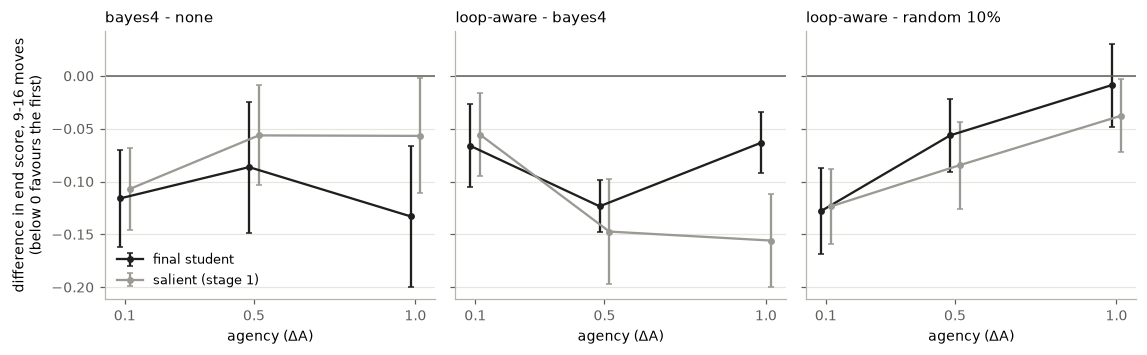

agency                                                                  ΔA 0.1  \
scope comparison                                                                 
9-16  1. bayes4 - none       -0.12 ± 0.05 (z -2.5, 18/24); salient -0.11, c...   
      2. loops - bayes4      -0.07 ± 0.04 (z -1.7, 16/24); salient -0.06, c...   
      3. loops - random 10%  -0.13 ± 0.04 (z -3.1, 17/24); salient -0.12, c...   
all   1. bayes4 - none       -0.26 ± 0.04 (z -6.7, 22/24); salient -0.18, c...   
      2. loops - bayes4      +0.01 ± 0.03 (z 0.4, 11/24); salient -0.05, ch...   
      3. loops - random 10%  -0.14 ± 0.03 (z -4.3, 20/24); salient -0.17, c...   

agency                                                                  ΔA 0.5  \
scope comparison                                                                 
9-16  1. bayes4 - none       -0.09 ± 0.06 (z -1.4, 14/24); salient -0.06, c...   
      2. loops - bayes4      -0.12 ± 0.02 (z -5.0, 21/24); salient -0.15, c...   
      3. loops - random 10%  -0.06 ± 0.03 (z -1.6, 15/24); salient -0.08, c...   
all   1. bayes4 - none       -0.25 ± 0.04 (z -6.0, 21/24); salient -0.23, c...   
      2. loops - bayes4      -0.08 ± 0.03 (z -3.0, 18/24); salient -0.07, c...   
      3. loops - random 10%  -0.07 ± 0.02 (z -3.3, 18/24); salient -0.08, c...   

agency                                                                    ΔA 1  
scope comparison                                                                
9-16  1. bayes4 - none       -0.13 ± 0.07 (z -2.0, 14/24); salient -0.06, c...  
      2. loops - bayes4      -0.06 ± 0.03 (z -2.2, 16/24); salient -0.16, c...  
      3. loops - random 10%  -0.01 ± 0.04 (z -0.2, 11/24); salient -0.04, c...  
all   1. bayes4 - none       -0.29 ± 0.04 (z -7.5, 24/24); salient -0.23, c...  
      2. loops - bayes4      -0.05 ± 0.03 (z -1.8, 17/24); salient -0.13, c...  
      3. loops - random 10%  -0.04 ± 0.03 (z -1.5, 16/24); salient -0.11, c...

In [12]:
import loops_analysis as la

final = pd.read_csv(os.path.join(SUMMARY, "final_stage1.csv"))
final_ends = pd.read_csv(os.path.join(SUMMARY, "final_stage1_ends.csv"))
stage1 = pd.read_csv(os.path.join(SUMMARY, "loops_stage1.csv")).query("student == 'salient'")
COMPARISONS = ["1. bayes4 - none", "2. loops - bayes4", "3. loops - random 10%"]
fig, axes = plt.subplots(1, 3, figsize=(10.5, 3.3), sharey=True)
for ax, name in zip(axes, COMPARISONS):
    for label, df, color, dx in (("final student", final, INK, -0.015), ("salient (stage 1)", stage1, "#9a9993", 0.015)):
        d = df[(df.scope == "9-16") & (df.comparison == name)].sort_values("agency")
        ax.errorbar(d.agency + dx, d["diff"], yerr=d.se, fmt="o-", ms=3.5, capsize=2, color=color, label=label)
    ax.axhline(0, color=MUTED, lw=1)
    ax.set_title(name[3:].replace("loops", "loop-aware"))
    ax.set_xlabel("agency (ΔA)")
    ax.set_xticks(la.AGENCIES)
    tidy(ax)
axes[0].set_ylabel("difference in end score, 9-16 moves\n(below 0 favours the first)")
axes[0].legend()
plt.tight_layout()
plt.show()

f1 = final[final.comparison.isin(COMPARISONS)].copy()
f1["cell"] = (f1["diff"].map("{:+.2f}".format) + " ± " + f1.se.map("{:.2f}".format) + " (z " + f1.z.map("{:.1f}".format)
              + ", " + f1.better + "); salient " + f1.salient.map("{:+.2f}".format) + ", change z "
              + (f1.change / f1.change_se).map("{:+.1f}".format))
f1.pivot_table(index=["scope", "comparison"], columns="agency", values="cell", aggfunc="first") \
    .reindex(["9-16", "all"], level=0).rename(columns="ΔA {:g}".format)

In [13]:
ends_both = pd.concat([final_ends, pd.read_csv(os.path.join(SUMMARY, "loops_stage1_ends.csv")).query(
    "student == 'salient'")])
ends_both[ends_both.scope == "9-16"].pivot_table(index="teacher", columns=["student", "agency"],
                                                 values=["end", "shown"]).style.format("{:.3f}", na_rep="") \
    .set_caption("9-16 moves: end score and share of moves shown")

In the panels and the table a negative difference favours the first teacher named; (k/24) counts the students it
favours; "change z" is the final student's difference minus the salient student's, over its SE.

- **Stage 1's conclusions carry over.** All nine primary differences have the salient student's sign, and none moves
  by more than 2 SE (the largest, loop-aware against bayes4 at ΔA 1, by +0.09, z +1.8). Untaught, the final student
  scores 3.51 on people's lengths, the salient one 3.54: it loops about as little.
- **1. bayes4 helps** by −0.12 at ΔA 0.1 (z −2.5, 18/24), −0.09 at 0.5 (z −1.4) and −0.13 at 1 (z −2.0); the salient
  student −0.11, −0.06 and −0.06. On all the tests, −0.25 to −0.29 (21-24 of 24).
- **2. Loop-aware bayes4 beats bayes4** at every ΔA: −0.07 (z −1.7), −0.12 (z −5.0, 21/24) and −0.06 (z −2.2). Its gain
  at ΔA 1 is smaller than on the salient student (−0.16) because bayes4 alone helps the final student more there; the
  loop-aware teacher's own effect is the same (−0.20 against −0.21 from no teacher). On all the tests: a tie at ΔA 0.1,
  −0.08 at 0.5, −0.05 at 1, as on the soft student in stage 1.
- **3. Against random help at its own spend**, loop-aware bayes4 is better at ΔA 0.1 (−0.13, z −3.1), leans better at
  0.5 (−0.06, z −1.6) and ties at 1 (−0.01). It shows 8.1-8.8% of moves against random's 10% (bayes4 4.9-5.3%).
  Random 10%'s effect grows with ΔA (−0.05, −0.15, −0.19 from no teacher) while the loop-aware teacher's stays
  −0.18 to −0.21: the assistance dilemma's shape again, where help chosen by the student's state matters most when
  shown moves are worth little.
- **Caveats, as in stage 1.** Loop-aware bayes4 also shows more than bayes4, so comparison 2 mixes noticing loops with
  showing more; comparison 3 is the one at equal spend. With 9 primary tests a Bonferroni cut is |z| > 2.8; two cells
  clear it, loop-aware against bayes4 at ΔA 0.5 and against random at 0.1 (in stage 1 four did).